# Bond-fit — binary classification

**Question:** does this actor's face *resemble* the six Eon-era Bonds?

This is **not** "is this person a good Bond". It is a similarity score against a
tiny, homogeneous positive class. Read it as *resemblance to past Bonds*, and
read the output as a **rank / AUC**, never as accuracy.

**Task shape**

| | |
|---|---|
| Positive class | the six Eon Bonds, `isBond == 1` in `dataset/actors.csv` |
| Negative class | real non-Bond actors, `isBond == 0` in `dataset/actors.csv` |
| Scoring only | `dataset/candidates.csv` — the actors being ranked. **Never** trained on |
| Features | 512-d InsightFace `buffalo_l` embeddings, L2-normalised |
| Headline metric | ROC-AUC / AP under leave-one-**actor**-out CV |

> ### Two rules this notebook enforces
> 1. **Candidates are scoring-only.** They are held out of training *and* out of
>    every CV fold, by construction, before any split is made. A model that
>    trained on an actor cannot then tell you anything about that actor.
> 2. **The unit of evaluation is the actor, not the image.** Six photos of the
>    same person are not six independent observations. Image-level numbers are
>    shown too, but labelled for what they are: inflated.

**Pipeline**

```
pictures/<initials>/*.jpg
        |  FaceModel/build_embeddings.py
        v
dataset/embeddings.npy  (n, 512) float32, L2-normalised
dataset/embeddings.csv  same values + actor_id, image_id
dataset/images.csv      one row per image: status, qc_flag, path, bbox, det_score
dataset/actors.csv      actor_id, isBond, heightCm, ...   <- the ONLY training data
dataset/candidates.csv  the actors being scored            <- never training data
        |
        v
classification.ipynb   <- you are here
```

## 1. Setup

In [99]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve)
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 0
HOLDOUT_ACTOR = "tom-holland"     # a candidate, so it is held out automatically

# Fixed settings. Nothing below selects these from a sweep -- picking the k and C
# that scored best on the CV is a second use of the same data, and at this sample
# size it buys optimism rather than accuracy. See section 7b.
K_PCA = 5
C_LOGREG = 0.3

# A real negative class, or there is nothing to learn from.
MIN_NEG_ACTORS = 25               # non-Bond actors required in actors.csv
MIN_NEG_IMAGES = 5                # kept images required per negative actor
# A candidate needs enough photos that a mean over images means something.
MIN_CAND_IMAGES = 5

# Works no matter which directory the kernel was started from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset").is_dir())
DATASET = ROOT / "dataset"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

# Three categorical slots (blue / orange / aqua -- the all-pairs safe set), a
# diverging pair for the heatmap, and neutral chrome.
C_BOND, C_NEG, C_CAND = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
GREYED = "#c3c2b7"
DIVERGING = ["#0d366b", "#1c5cab", "#2a78d6", "#86b6ef", "#cde2fb",
             "#f0efec",
             "#fbd5d4", "#f0a9a8", "#e34948", "#b02a29", "#7c1b1a"]


def tidy(ax, grid_axis=None):
    # Hairline grid, no top/right spine -- chrome recedes, data stays.
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def pretty(actor_id: str) -> str:
    return str(actor_id).replace("-", " ").title()


print("project root:", ROOT)
print("figures     :", FIGURES)

project root: c:\Users\Bureau\OneDrive\Bureau\JamesBond AI
figures     : c:\Users\Bureau\OneDrive\Bureau\JamesBond AI\figures


## 2. Load and join

Training metadata comes from **`dataset/actors.csv` alone** — the six Bonds plus
real non-Bond actors. The candidate file is read into its own frame and never
joins the training side; an actor is either training data or a candidate, never
both, and that is an assert rather than a convention.

In [100]:
# ---------------------------------------------------------------- training data
actors = pd.read_csv(DATASET / "actors.csv")
assert "isBond" in actors.columns, "actors.csv needs an isBond column"
assert "actor_id" in actors.columns, "actors.csv needs an actor_id column"


# ------------------------------------------------------------- the candidates
def read_candidates(dataset: Path) -> pd.DataFrame:
    # The file is candidates.csv in this repo; candidate.csv is accepted too.
    for name in ("candidate.csv", "candidates.csv"):
        path = dataset / name
        if path.exists() and path.stat().st_size > 0:
            print(f"  candidates <- {name}")
            return pd.read_csv(path)
    raise FileNotFoundError(f"no candidate.csv / candidates.csv under {dataset}")


cand = read_candidates(DATASET)

leaked = sorted(set(cand["actor_id"]) & set(actors["actor_id"]))
assert not leaked, (
    f"candidate leaked into training: {leaked} appear in BOTH actors.csv and the\n"
    "candidate file. An actor is either training data or a candidate being\n"
    "scored -- keeping them in both is what made the old scores meaningless."
)
assert HOLDOUT_ACTOR not in set(actors["actor_id"]), (
    f"{HOLDOUT_ACTOR} is a training actor; it must stay a candidate"
)

print(f"  actors.csv      {len(actors)} actor(s)  "
      f"({int(actors['isBond'].sum())} Bond / "
      f"{int((actors['isBond'] == 0).sum())} negative)")
print(f"  candidates      {len(cand)} candidate(s), scoring only")

X = np.load(DATASET / "embeddings.npy").astype(np.float64)
meta = pd.read_csv(DATASET / "embeddings.csv", usecols=["actor_id", "image_id"])
images = pd.read_csv(DATASET / "images.csv")

# One label table: Bonds and negatives from actors.csv, candidates from `cand`.
# Candidates carry isBond = 0 so the merge is total, but isCandidate marks them
# so they can be separated again before any split.
known = pd.concat([
    actors.assign(isCandidate=0, isBond=actors["isBond"].astype(int)),
    cand.assign(isCandidate=1, isBond=0),
], ignore_index=True)
for col in ("isBond", "isCandidate", "heightCm", "initials", "firstName",
            "secondName", "birthYear"):
    if col not in known.columns:
        known[col] = np.nan
assert known["actor_id"].is_unique, "an actor_id appears twice in the label table"

# Display names, taken from the CSVs so hyphens and accents survive.
NAMES = {r.actor_id: f"{r.firstName} {r.secondName}" for r in known.itertuples()
         if isinstance(r.firstName, str) and isinstance(r.secondName, str)}


def name_of(actor_id) -> str:
    return NAMES.get(actor_id, pretty(actor_id))


df = (meta
      .merge(images[["image_id", "status", "qc_flag", "path", "bbox", "det_score"]],
             on="image_id", how="left")
      .merge(known[["actor_id", "isBond", "isCandidate", "heightCm", "initials",
                    "firstName", "secondName", "birthYear"]],
             on="actor_id", how="left"))
df["qc_flag"] = df["qc_flag"].fillna("")

print(f"\nX {X.shape} | rows {len(df)} | actors {df['actor_id'].nunique()}")
df[["actor_id", "image_id", "status", "qc_flag", "isBond", "isCandidate"]].head(8)

  candidates <- candidates.csv
  actors.csv      36 actor(s)  (6 Bond / 30 negative)
  candidates      12 candidate(s), scoring only

X (253, 512) | rows 253 | actors 48


,actor_id,image_id,status,qc_flag,isBond,isCandidate
0,aaron-taylor-johnson,aaron-taylor-johnson/Aaron-Taylor-Johnson-Nosf...,kept,,0,1
1,aaron-taylor-johnson,aaron-taylor-johnson/imgi_159_Aaron_Taylor-Joh...,kept,,0,1
2,aaron-taylor-johnson,aaron-taylor-johnson/imgi_161_SEI256010343.jpg,kept,,0,1
3,aaron-taylor-johnson,aaron-taylor-johnson/imgi_175_english-actor-aa...,kept,,0,1
4,aaron-taylor-johnson,aaron-taylor-johnson/imgi_191_aaron-taylor-joh...,kept,multi_face,0,1
5,aaron-taylor-johnson,aaron-taylor-johnson/imgi_201_aaron-taylor-joh...,kept,,0,1
6,ben-affleck,ben-affleck/imgi_143_Ben_Affleck_at_83rd_Venic...,kept,,0,0
7,ben-affleck,ben-affleck/imgi_149_Actor-Ben-Affleck-premier...,kept,,0,0


### Sanity checks

A silent `X` / label misalignment produces a great-looking score with no meaning,
so these are asserts, not printouts.

In [101]:
assert X.shape[0] == len(df) == len(meta), "X / df / meta length mismatch"
assert df["image_id"].is_unique, "duplicate image_id"
assert not np.isnan(X).any(), "NaN in embeddings"
assert df["isBond"].notna().all(), (
    "an actor_id in embeddings.csv is in neither actors.csv nor the candidate file"
)

norms = np.linalg.norm(X, axis=1)
print(f"row norms: min {norms.min():.4f}  max {norms.max():.4f}  (expect 1.0)")
print("Bond actors    :", int(df.loc[df["isBond"] == 1, "actor_id"].nunique()))
print("negative actors:", int(df.loc[(df["isBond"] == 0) & (df["isCandidate"] == 0),
                                   "actor_id"].nunique()))
print("candidates     :", int(df.loc[df["isCandidate"] == 1, "actor_id"].nunique()),
      "(scoring only)")

row norms: min 1.0000  max 1.0000  (expect 1.0)
Bond actors    : 6
negative actors: 30
candidates     : 12 (scoring only)


### Guard — the binary task needs a real negative class

The candidates are the people being **scored**. Using them as negatives trains the
model to answer the question it is being asked, so every candidate score comes back
"not Bond" and the ranking is meaningless. The negative class has to be actors who
are genuinely not Bonds and are not candidates.

This fails loudly rather than returning a plausible-looking number.

In [102]:
neg_actors = sorted(set(actors.loc[actors["isBond"] == 0, "actor_id"]))
kept = df[df["status"] == "kept"]
neg_counts = kept[kept["actor_id"].isin(neg_actors)].groupby("actor_id").size()

too_few = len(neg_actors) < MIN_NEG_ACTORS
short = [a for a in neg_actors if int(neg_counts.get(a, 0)) < MIN_NEG_IMAGES]

if too_few or short:
    lines = []
    if too_few:
        lines.append(f"  only {len(neg_actors)} negative actor(s) in actors.csv; "
                     f"need >= {MIN_NEG_ACTORS}")
    if short:
        lines.append(f"  negative actors with too few kept images "
                     f"(need >= {MIN_NEG_IMAGES} each):")
        lines += [f"      {a:<20} {int(neg_counts.get(a, 0))} kept image(s)"
                  for a in short]
    raise RuntimeError(
        "Bond-fit cannot be evaluated on this dataset.\n"
        + "\n".join(lines)
        + "\n\nThe candidates in the candidate file are NOT negatives -- they are the\n"
        "people being scored. Training on them forces every candidate score low.\n\n"
        "To fix:\n"
        "  1. add real non-Bond actors to dataset/actors.csv with isBond = 0\n"
        "     (aim for 25+, varied in age, ethnicity and look)\n"
        "  2. drop 5+ photos each in pictures/<initials>/\n"
        "  3. re-run: python FaceModel/build_embeddings.py\n"
        "  4. restart the kernel and run this notebook top to bottom.\n"
    )

print(f"OK - {len(neg_actors)} negative actor(s), "
      f"{int(df['isBond'].eq(1).sum())} Bond image(s), "
      f"{int(df['isBond'].eq(0).sum())} negative image(s)")

OK - 30 negative actor(s), 30 Bond image(s), 223 negative image(s)


## 3. Filter and align

Drop rejected images, and drop the `multi_face` shots: `build_embeddings.py` keeps
the *largest* face in a group photo, which may not be the actor it is filed under.

Then split on actor identity — candidates out of every array that training or CV
touches, before any fold is drawn.

In [103]:
keep = (df["status"] == "kept") & (~df["qc_flag"].str.contains("multi_face", na=False))
print(f"dropping {int((~keep).sum())} row(s):")
print(df.loc[~keep, ["image_id", "status", "qc_flag"]].to_string(index=False))

df = df.loc[keep].reset_index(drop=True)
X = X[keep.to_numpy()]

y_all = df["isBond"].to_numpy().astype(int)
groups_all = df["actor_id"].to_numpy()

# Candidates are out before anything else happens.
train_actors = set(actors["actor_id"])
is_train = df["actor_id"].isin(train_actors).to_numpy()
is_cand = ~is_train

assert not (set(groups_all[is_cand]) & train_actors), "candidate in the training set"
assert not (df.loc[is_train, "isCandidate"] == 1).any(), "an isCandidate row is training"
assert HOLDOUT_ACTOR not in train_actors, f"{HOLDOUT_ACTOR} leaked into training"

X_tr, y_tr, g_tr = X[is_train], y_all[is_train], groups_all[is_train]
X_cand, g_cand, cand_ids = X[is_cand], groups_all[is_cand], sorted(set(groups_all[is_cand]))

print(f"\ntraining/CV : {len(X_tr)} images, {len(set(g_tr))} actors "
      f"({y_tr.sum()} pos / {(y_tr == 0).sum()} neg)")
print(f"candidates  : {len(X_cand)} images, {len(cand_ids)} actors "
      "(never in training, never in a fold)")

dropping 11 row(s):
                                                                                                     image_id status    qc_flag
                                         aaron-taylor-johnson/imgi_191_aaron-taylor-johnson-66d962602becd.jpg   kept multi_face
                                                                         colin-firth/imgi_161_Colin-Firth.jpg   kept multi_face
                                              callum-turner/imgi_127_gettyimages-2232904180-695ba8cc7249b.jpg   kept multi_face
                                                                                         daniel-craig/DC5.jpg   kept multi_face
                                                                     eric-bana/imgi_163_ericbana-5-scaled.jpg   kept multi_face
                                       george-clooney/imgi_222_George_Clooney_83rd_Venice_Film_Festival_2.jpg   kept multi_face
                                                              henry-cavill/imgi_203_

## 4. Image paths

`images.csv` stores paths as `pictures\\DC\\007.jpg` — Windows separators. They are
fine as *strings* on Windows and broken everywhere else, so normalise to a portable
`Path` before using one to open a file.

In [104]:
def to_path(raw) -> Path:
    # Normalise the separator, then resolve relative to the project root.
    p = Path(str(raw).replace("\\", "/"))
    return p if p.is_absolute() else ROOT / p


missing = [r for r in df["path"] if not to_path(r).exists()]
print("images referenced:", len(df), " missing on disk:", len(missing))
assert not missing, f"missing image file(s): {missing[:3]}"

images referenced: 242  missing on disk: 0


## 5. Evaluation harness

`LeaveOneGroupOut` holds out one **actor** per fold, so no photo of the test person
was ever seen. Because a fold's test set is a single actor, a per-fold AUC is
undefined; metrics are computed once over the pooled out-of-fold scores.

Two levels of evaluation, and the order matters:

| level | rows | status |
|---|---|---|
| **actor** (section 8) | one per actor | **the headline** |
| image (sections 6–7) | one per photo | inflated — photos of one actor are not independent |

In [105]:
class ClampedPCA(BaseEstimator, TransformerMixin):
    # PCA, but n_components is clamped to what this fold's data can support.
    def __init__(self, n_components=5):
        self.n_components = n_components

    def fit(self, X, y=None):
        k = max(1, min(self.n_components, X.shape[0] - 1, X.shape[1]))
        self.pca_ = PCA(n_components=k, random_state=RANDOM_STATE).fit(X)
        return self

    def transform(self, X):
        return self.pca_.transform(X)

In [106]:
def group_oof_scores(estimator, X, y, groups):
    # Out-of-fold P(positive) for every row; each fold hides a whole actor.
    scores = np.full(len(y), np.nan)
    for tr, te in LeaveOneGroupOut().split(X, y, groups):
        model = clone(estimator).fit(X[tr], y[tr])
        scores[te] = model.predict_proba(X[te])[:, 1]
    assert not np.isnan(scores).any(), "a row was never scored"
    return scores


def score_summary(scores, y):
    return {
        "roc_auc": round(roc_auc_score(y, scores), 3),
        "average_precision": round(average_precision_score(y, scores), 3),
        "n_positive": int(y.sum()),
        "n_negative": int((y == 0).sum()),
    }


# --- actor level -------------------------------------------------------------

def actor_labels(groups, y):
    # Actor order and per-actor labels, computed once so every actor-level metric
    # below uses the same order.
    acts = np.array(sorted(set(groups)))
    return acts, np.array([int(y[groups == a][0]) for a in acts])


def actor_oof_scores(estimator, X, y, groups):
    # Leave-one-actor-out at the ACTOR level: one row in, one score out. Train on
    # every image of the training actors, score the held-out actor by the mean
    # P(Bond-like) over their images.
    acts, y_act = actor_labels(groups, y)
    scores = np.full(len(acts), np.nan)
    probe = np.zeros((len(acts), 1))          # the split is driven by `acts`
    for tr, te in LeaveOneGroupOut().split(probe, y_act, acts):
        in_tr = np.isin(groups, acts[tr])
        model = clone(estimator).fit(X[in_tr], y[in_tr])
        for j in te:
            scores[j] = model.predict_proba(X[groups == acts[j]])[:, 1].mean()
    assert not np.isnan(scores).any(), "an actor was never scored"
    return scores, y_act, acts


def actor_centroid_scores(X, y, groups):
    # Same folds, no training: cosine to the mean face of the training Bonds.
    acts, y_act = actor_labels(groups, y)
    scores = np.full(len(acts), np.nan)
    probe = np.zeros((len(acts), 1))
    for tr, te in LeaveOneGroupOut().split(probe, y_act, acts):
        in_tr = np.isin(groups, acts[tr]) & (y == 1)
        c = X[in_tr].mean(axis=0)
        c /= np.linalg.norm(c)
        for j in te:
            scores[j] = float((X[groups == acts[j]] @ c).mean())
    return scores, y_act, acts


def bond_ranks_actors(scores, y_act, acts):
    # Where each Bond's out-of-fold score falls among the negative ACTORS.
    # A Bond below every negative ranks last at len(neg)/len(neg), not len+1.
    neg = scores[y_act == 0]
    rows = []
    for a in sorted(set(acts[y_act == 1])):
        s = float(scores[acts == a][0])
        above = int((neg > s).sum())
        rows.append({
            "actor_id": a,
            "mean_score": round(s, 4),
            "negatives_above": above,
            "rank": f"{min(above + 1, len(neg))}/{len(neg)}",
            "separation": round(float((neg < s).mean()), 3),
        })
    return pd.DataFrame(rows).sort_values("mean_score", ascending=False).reset_index(drop=True)

## 6. Baseline — cosine similarity to the Bond centroid (image level)

No training: each fold averages the *training* Bonds into one centroid and scores
every image by cosine similarity to it. The centroid is rebuilt per fold, so the
held-out actor is never in it.

Kept as a reference point for the image-level numbers in section 7. The actor-level
version of the same baseline is in section 8, next to the headline.

In [107]:
def centroid_oof_scores(X, y, groups):
    scores = np.full(len(y), np.nan)
    for tr, te in LeaveOneGroupOut().split(X, y, groups):
        pos = X[tr][y[tr] == 1]
        c = pos.mean(axis=0)
        c /= np.linalg.norm(c)
        scores[te] = X[te] @ c
    return scores


base_scores = centroid_oof_scores(X_tr, y_tr, g_tr)
print("Bond-centroid cosine baseline, image level")
print(score_summary(base_scores, y_tr))

Bond-centroid cosine baseline, image level
{'roc_auc': 0.774, 'average_precision': 0.545, 'n_positive': 29, 'n_negative': 145}


## 7. Logistic regression — the k x C sweep

`StandardScaler -> PCA(k) -> LogisticRegression(C, class_weight="balanced")`.

The sweep below is a **diagnostic**: it shows how sensitive the result is to the two
knobs. Nothing is selected from it. The shipped model uses the fixed `K_PCA` and
`C_LOGREG` from section 1.

In [108]:
def build_logreg(k=K_PCA, C=C_LOGREG):
    return Pipeline([
        ("scale", StandardScaler()),
        ("pca", ClampedPCA(k)),
        ("clf", LogisticRegression(
            C=C, max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE,
        )),
    ])

In [109]:
K_GRID = [3, 5, 8, 10, 15]
C_GRID = [0.01, 0.1, 0.3, 1.0, 10.0]

rows = []
for k in K_GRID:
    for C in C_GRID:
        s = group_oof_scores(build_logreg(k, C), X_tr, y_tr, g_tr)
        rows.append({"k": k, "C": C,
                     "roc_auc": round(roc_auc_score(y_tr, s), 3),
                     "avg_precision": round(average_precision_score(y_tr, s), 3)})
sweep = pd.DataFrame(rows)

print("ROC-AUC  (k = rows, C = columns), image level")
display(sweep.pivot(index="k", columns="C", values="roc_auc"))
print("average precision, image level")
display(sweep.pivot(index="k", columns="C", values="avg_precision"))

per_k = sweep.groupby("k")["roc_auc"].agg(["min", "max"])
per_k["spread"] = per_k["max"] - per_k["min"]
print(per_k.round(3).to_string())
print(f"\nROC-AUC across k: min {sweep['roc_auc'].min():.3f}  "
      f"max {sweep['roc_auc'].max():.3f}  "
      f"spread {sweep['roc_auc'].max() - sweep['roc_auc'].min():.3f}")

ROC-AUC  (k = rows, C = columns), image level


C,0.01,0.10,0.30,1.00,10.00
k,,,,,
3,0.467,0.456,0.455,0.454,0.454
5,0.571,0.530,0.524,0.523,0.522
8,0.687,0.665,0.661,0.679,0.755
10,0.753,0.757,0.766,0.806,0.877
15,0.765,0.789,0.803,0.822,0.847


average precision, image level


C,0.01,0.10,0.30,1.00,10.00
k,,,,,
3,0.153,0.152,0.152,0.152,0.152
5,0.253,0.239,0.238,0.237,0.237
8,0.464,0.459,0.440,0.441,0.472
10,0.522,0.510,0.489,0.504,0.574
15,0.499,0.481,0.492,0.495,0.512


      min    max  spread
k                       
3   0.454  0.467   0.013
5   0.522  0.571   0.049
8   0.661  0.755   0.094
10  0.753  0.877   0.124
15  0.765  0.847   0.082

ROC-AUC across k: min 0.454  max 0.877  spread 0.423


> **A large spread across `k` means the result is noise.** The same data, the same
> folds, the same model — only the number of PCA components changed — and the AUC
> moves by more than the gap between the best and worst model in the table above.
> When that happens, the ordering of the table is not a finding: no configuration
> is better than any other, and quoting the top cell's number is quoting noise.
> Report the spread, not the maximum. This is why `K_PCA` is fixed in section 1
> rather than picked from this grid.

### 7b. The fixed settings, at image level — **inflated**

These are the numbers to *not* quote. A fold holds out one actor at a time, so the
model never saw the test actor's face — but the test set is still five photos of
that one person, and those five rows all succeed or all fail together. Pooling them
counts one person's face five times, which flatters both AUC and AP.

In [110]:
lr_scores = group_oof_scores(build_logreg(), X_tr, y_tr, g_tr)
image_level = pd.DataFrame([
    {"model": "Bond-centroid cosine", **score_summary(base_scores, y_tr)},
    {"model": f"LogReg PCA({K_PCA}) C={C_LOGREG}", **score_summary(lr_scores, y_tr)},
])
print("Image level -- INFLATED: photos of one actor are not independent samples.")
print("Read section 8 instead.\n")
image_level

Image level -- INFLATED: photos of one actor are not independent samples.
Read section 8 instead.



,model,roc_auc,average_precision,n_positive,n_negative
0,Bond-centroid cosine,0.774,0.545,29,145
1,LogReg PCA(5) C=0.3,0.524,0.238,29,145


## 8. Actor-level results — **the headline**

One row per actor. Each actor is scored by a model trained on the other actors
only, then that actor's images are averaged into a single number. This is the only
place in the notebook where the unit of evaluation matches the unit of the claim
("which *actor* resembles the Bonds"), and it is the number to report.

`n` is small — one actor is one data point — so AUC here is a coarse ranking
diagnostic. The per-Bond ranks are part of the result, not a footnote.

In [111]:
act_scores, y_act, acts = actor_oof_scores(build_logreg(), X_tr, y_tr, g_tr)
act_base, y_act_b, acts_b = actor_centroid_scores(X_tr, y_tr, g_tr)
assert (acts == acts_b).all() and (y_act == y_act_b).all(), "baselines disagree on actor order"

act_auc = roc_auc_score(y_act, act_scores)
act_ap = average_precision_score(y_act, act_scores)
base_auc = roc_auc_score(y_act, act_base)
base_ap = average_precision_score(y_act, act_base)

print(f"actor-level, leave-one-actor-out: {len(acts)} actors "
      f"({int(y_act.sum())} Bond / {int((y_act == 0).sum())} negative)\n")
pd.DataFrame([
    {"model": "Bond-centroid cosine",
     "roc_auc": round(base_auc, 3), "average_precision": round(base_ap, 3)},
    {"model": f"LogReg PCA({K_PCA}) C={C_LOGREG}",
     "roc_auc": round(act_auc, 3), "average_precision": round(act_ap, 3)},
])

actor-level, leave-one-actor-out: 36 actors (6 Bond / 30 negative)



,model,roc_auc,average_precision
0,Bond-centroid cosine,0.783,0.626
1,LogReg PCA(5) C=0.3,0.506,0.310


In [112]:
print(f"HEADLINE  actor-level ROC-AUC {act_auc:.3f}   AP {act_ap:.3f}")
print(f"baseline  actor-level ROC-AUC {base_auc:.3f}   AP {base_ap:.3f}")
if base_auc >= act_auc:
    print("\nThe training-free centroid is at least as good. The extra capacity of\n"
          "logistic regression is not buying anything on this data.")

ranks = bond_ranks_actors(act_scores, y_act, acts)
print(f"\nper-Bond rank among the {int((y_act == 0).sum())} negative actors:")
ranks

HEADLINE  actor-level ROC-AUC 0.506   AP 0.310
baseline  actor-level ROC-AUC 0.783   AP 0.626

The training-free centroid is at least as good. The extra capacity of
logistic regression is not buying anything on this data.

per-Bond rank among the 30 negative actors:


,actor_id,mean_score,negatives_above,rank,separation
0,george-lazenby,0.5521,1,2/30,0.967
1,roger-moore,0.5060,3,4/30,0.900
2,sean-connery,0.4753,3,4/30,0.900
3,pierce-brosnan,0.1974,25,26/30,0.167
4,timothy-dalton,0.1411,27,28/30,0.100
5,daniel-craig,0.0000,30,30/30,0.000


In [113]:
# Actor-level score for every training actor, Bonds and negatives side by side.
pd.DataFrame({
    "actor_id": acts,
    "isBond": y_act,
    "actor_oof_score": np.round(act_scores, 4),
    "centroid_score": np.round(act_base, 4),
}).sort_values("actor_oof_score", ascending=False).reset_index(drop=True)

,actor_id,isBond,actor_oof_score,centroid_score
0,bradley-cooper,0,0.5541,0.1189
1,george-lazenby,1,0.5521,0.2188
2,jason-statham,0,0.5484,-0.0079
3,harrison-ford,0,0.5397,0.1411
4,roger-moore,1,0.5060,0.1558
5,sean-connery,1,0.4753,0.1079
6,ben-affleck,0,0.4642,0.1631
7,keanu-reeves,0,0.4572,0.0593
8,mel-gibson,0,0.4117,0.1090
9,jude-law,0,0.3986,0.0833


## 9. Robustness — repeated subsampling of the negative actors

With a few dozen negatives, the single CV number above moves when one hard actor is
added or removed. Resample 80% of the negative actors 20 times, keep every Bond,
re-run the actor-level CV, and report the spread. **The std is the honest error bar
on everything above** — if it is large, the ranking is a coin flip and no amount of
decimal places fixes that.

In [114]:
N_REPEATS = 20
NEG_FRACTION = 0.80
rng = np.random.default_rng(RANDOM_STATE)

neg_ids = acts[y_act == 0]
pos_ids = acts[y_act == 1]
n_keep = max(2, int(round(len(neg_ids) * NEG_FRACTION)))

rep_auc, rep_ap = [], []
for _ in range(N_REPEATS):
    picked = neg_ids[rng.permutation(len(neg_ids))[:n_keep]]
    sel = is_train & np.isin(groups_all, np.concatenate([pos_ids, picked]))
    s, ya, _ = actor_oof_scores(build_logreg(), X[sel], y_all[sel], groups_all[sel])
    rep_auc.append(roc_auc_score(ya, s))
    rep_ap.append(average_precision_score(ya, s))

rep_auc = np.asarray(rep_auc)
rep_ap = np.asarray(rep_ap)
print(f"{N_REPEATS} runs, {n_keep} of {len(neg_ids)} negative actors each "
      f"({NEG_FRACTION:.0%}), all {len(pos_ids)} Bonds kept\n")
print(f"  ROC-AUC  mean {rep_auc.mean():.3f}  std {rep_auc.std():.3f}  "
      f"min {rep_auc.min():.3f}  max {rep_auc.max():.3f}")
print(f"  AP       mean {rep_ap.mean():.3f}  std {rep_ap.std():.3f}")
print("\nQuote the mean with the std. A std near 0.1 means the headline AUC above\n"
      "is one draw from a wide distribution, not a property of the model.")

20 runs, 24 of 30 negative actors each (80%), all 6 Bonds kept

  ROC-AUC  mean 0.606  std 0.076  min 0.458  max 0.750
  AP       mean 0.472  std 0.098

Quote the mean with the std. A std near 0.1 means the headline AUC above
is one draw from a wide distribution, not a property of the model.


## 10. Does the camera give it away? Photo-source check

The Bond photos and the non-Bond photos were collected from different places, at
different times, in different lighting. A classifier that sees **only image
metadata** — detector confidence, face-box size and shape, image dimensions — must
not be able to tell Bond from non-Bond. If it can, part of the face-embedding
signal is really "which photoshoot / which website this came from", and every
number above is partly a measurement of the photo source.

In [115]:
def meta_features(frame: pd.DataFrame):
    # No face pixels, no embeddings -- only how the photo was taken and how big
    # the detector thought the face was.
    import cv2

    parts = frame["bbox"].astype(str).str.split(",", expand=True).iloc[:, :4].astype(float)
    fw = (parts[2] - parts[0]).to_numpy()
    fh = (parts[3] - parts[1]).to_numpy()

    img_w, img_h = [], []
    for raw in frame["path"]:
        im = cv2.imread(str(to_path(raw)))
        img_h.append(im.shape[0] if im is not None else np.nan)
        img_w.append(im.shape[1] if im is not None else np.nan)

    F = np.column_stack([frame["det_score"].to_numpy(float), fw, fh,
                         np.asarray(img_w, float), np.asarray(img_h, float), fw * fh])
    names = ["det_score", "face_w", "face_h", "img_w", "img_h", "face_area"]
    return np.nan_to_num(F, nan=0.0), names


train_frame = df.loc[is_train].reset_index(drop=True)
F_meta, meta_names = meta_features(train_frame)

meta_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])
meta_scores = group_oof_scores(meta_pipe, F_meta, y_tr, g_tr)
meta_auc = roc_auc_score(y_tr, meta_scores)

print(f"photo-source AUC from metadata alone: {meta_auc:.3f}")
print("features:", ", ".join(meta_names))
if meta_auc > 0.65:
    print("\nWARNING: image metadata separates Bond from non-Bond at AUC > 0.65.\n"
          "The two classes were photographed differently, so part of what the face\n"
          "embeddings measure may be the photo source, not the face. Match the\n"
          "sources -- same kind of shot, same crop, same era of press photo --\n"
          "before trusting any number in this notebook.")
else:
    print("No strong source signal (AUC <= 0.65): the two classes look like they\n"
          "were collected on similar terms.")

photo-source AUC from metadata alone: 0.929
features: det_score, face_w, face_h, img_w, img_h, face_area

The two classes were photographed differently, so part of what the face
embeddings measure may be the photo source, not the face. Match the
sources -- same kind of shot, same crop, same era of press photo --
before trusting any number in this notebook.


## 11. Fitting the shipped model

Fit on all training data (Bonds + negative actors — never a candidate) and persist.
This is the artefact inference uses.

In [116]:
model = build_logreg().fit(X_tr, y_tr)

out = ROOT / "model.joblib"
joblib.dump({"model": model, "k": K_PCA, "C": C_LOGREG,
             "holdout_actor": HOLDOUT_ACTOR, "scoring_only": "candidates",
             "actor_level_auc": float(act_auc), "actor_level_ap": float(act_ap),
             "embedding_dim": X_tr.shape[1]}, out)

print("saved ->", out)
print("trained on", len(X_tr), "images from", len(set(g_tr)), "actors",
      f"({int(y_tr.sum())} Bond / {int((y_tr == 0).sum())} negative)")
print("in-sample accuracy (optimistic by construction):",
      round(model.score(X_tr, y_tr), 3))

saved -> c:\Users\Bureau\OneDrive\Bureau\JamesBond AI\model.joblib
trained on 174 images from 36 actors (29 Bond / 145 negative)
in-sample accuracy (optimistic by construction): 0.787


## 12. Scoring the candidates

Every candidate is out-of-sample **by construction**: the model has never seen a
candidate face, in training or in any fold. So unlike the old
candidates-as-negatives version, these scores are honest — they are simply the
model's answer about actors it was not told about.

A candidate with fewer than `MIN_CAND_IMAGES` kept photos is **listed as
insufficient, not scored**: a mean over one or two photos is that photo, not that
actor.

In [117]:
# Per-Bond mean face, from training actors only.
bond_means = {}
for b in sorted(set(g_tr[y_tr == 1])):
    c = X_tr[g_tr == b].mean(axis=0)
    bond_means[b] = c / np.linalg.norm(c)

# Cosine above which "nearest Bond" means something. Below it the winner of an
# argmax is whichever direction is least bad, which is not a fact about the face.
COSINE_MEANINGFUL = 0.30


def score_candidates(X_cand, g_cand, ids, min_images=MIN_CAND_IMAGES):
    rows = []
    for a in sorted(ids):
        n = int((g_cand == a).sum())
        rows.append({"actor_id": a, "n_images": n, "scored": n >= min_images})

    for r in rows:
        if not r["scored"]:
            r.update({"fit_probability": np.nan, "nearest_bond": None,
                      "nearest_bond_cosine": np.nan, "cosines": None})
            continue
        Z = X_cand[g_cand == r["actor_id"]]
        r["fit_probability"] = round(float(model.predict_proba(Z)[:, 1].mean()), 4)
        sims = {b: float((Z @ c).mean()) for b, c in bond_means.items()}
        r["nearest_bond"] = max(sims, key=sims.get)
        r["nearest_bond_cosine"] = round(sims[r["nearest_bond"]], 4)
        r["cosines"] = sims

    table = pd.DataFrame(rows)
    scored = (table[table["scored"]]
              .sort_values("fit_probability", ascending=False)
              .drop(columns="cosines").reset_index(drop=True))
    scored.insert(0, "rank", np.arange(1, len(scored) + 1))
    insufficient = table[~table["scored"]].drop(columns="cosines").reset_index(drop=True)
    return scored, insufficient

In [118]:
cand_table, cand_short = score_candidates(X_cand, g_cand, cand_ids)

print(f"actor-level CV ROC-AUC {act_auc:.3f}   (AP {act_ap:.3f})")
print(f"per-Bond rank among {int((y_act == 0).sum())} negative actors: "
      + ", ".join(ranks["rank"])
      + "   (negatives above each Bond: "
      + ", ".join(str(int(v)) for v in sorted(ranks["negatives_above"])) + ")")
if act_auc < 0.7:
    print("\nScores below are not reliable.")
print()

view = cand_table if len(cand_table) else pd.DataFrame(
    columns=["rank", "actor_id", "n_images", "scored", "fit_probability",
             "nearest_bond", "nearest_bond_cosine"])

best_cos = float(np.nanmax(view["nearest_bond_cosine"])) if len(view) else 0.0
if len(view) and best_cos <= COSINE_MEANINGFUL:
    print(f"No candidate reaches a cosine of {COSINE_MEANINGFUL} to any Bond "
          f"(best {best_cos:.3f}).\n"
          "At that distance 'nearest Bond' is an argmax over noise and is not "
          "reported.")
    view = view.drop(columns=["nearest_bond", "nearest_bond_cosine"])
view

actor-level CV ROC-AUC 0.506   (AP 0.310)
per-Bond rank among 30 negative actors: 2/30, 4/30, 4/30, 26/30, 28/30, 30/30   (negatives above each Bond: 1, 3, 3, 25, 27, 30)

Scores below are not reliable.

No candidate reaches a cosine of 0.3 to any Bond (best 0.167).
At that distance 'nearest Bond' is an argmax over noise and is not reported.


,rank,actor_id,n_images,scored,fit_probability
0,1,callum-turner,5,True,0.3988
1,2,james-norton,6,True,0.2867
2,3,theo-james,6,True,0.2771
3,4,tom-hardy,6,True,0.2686
4,5,harris-dickinson,6,True,0.2603
5,6,tom-holland,6,True,0.2554
6,7,jacob-elordi,6,True,0.2551
7,8,idris-elba,6,True,0.2523
8,9,rege-jean-page,6,True,0.2477
9,10,henry-cavill,5,True,0.2156


In [119]:
if len(cand_short):
    print(f"insufficient photos (< {MIN_CAND_IMAGES} kept images) -- listed, not scored:")
    display(cand_short)
else:
    print("every candidate has enough photos to be scored")

if len(cand_table) == 0:
    print(f"\nno candidate has >= {MIN_CAND_IMAGES} kept images, so nothing is "
          "ranked yet.\nAdd more photos per candidate in pictures/<initials>/ and "
          "re-run\nFaceModel/build_embeddings.py.")

every candidate has enough photos to be scored


In [120]:
def predict_fit(actor_id=None, image_paths=None, top_n=5):
    # Ad-hoc inference for one actor already in the dataset, or a list of photo
    # paths. Returns the mean P(Bond-like) and the cosine to each Bond.
    from pathlib import Path as _Path

    if (actor_id is None) == (image_paths is None):
        raise ValueError("pass exactly one of actor_id / image_paths")

    if actor_id is not None:
        if actor_id not in set(groups_all):
            raise KeyError(f"{actor_id!r} not in embeddings. known: {sorted(set(groups_all))}")
        Z = X[groups_all == actor_id]
    else:
        import cv2
        from insightface.app import FaceAnalysis

        global _APP
        if "_APP" not in globals():
            _APP = FaceAnalysis(name="buffalo_l")
            _APP.prepare(ctx_id=0, det_size=(640, 640))
        vectors = []
        for p in image_paths:
            img = cv2.imread(str(to_path(p)))
            if img is None:
                raise FileNotFoundError(p)
            faces = _APP.get(img)
            if not faces:
                raise ValueError(f"no face detected in {p}")
            face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
            vectors.append(face.normed_embedding.astype(np.float64))
        Z = np.vstack(vectors)

    sims = {b: float((Z @ c).mean()) for b, c in bond_means.items()}
    nearest = max(sims, key=sims.get)
    result = {
        "fit_probability": round(float(model.predict_proba(Z)[:, 1].mean()), 4),
        "n_images": int(len(Z)),
        "cosine_to_bonds": {b: round(v, 4) for b, v in
                            sorted(sims.items(), key=lambda kv: -kv[1])},
    }
    if sims[nearest] > COSINE_MEANINGFUL:
        result["nearest_bond"] = nearest
    else:
        result["nearest_bond"] = (f"none -- best cosine {sims[nearest]:+.3f} is below "
                                  f"{COSINE_MEANINGFUL}")
    return result


# predict_fit(actor_id="pierce-brosnan")
# predict_fit(image_paths=["pictures/PB/PB2.jpg"])

## 13. Visualizations

Eight figures, saved to `figures/` at 150 dpi. matplotlib only.

| figure | what it answers |
|---|---|
| `pca_face_space.png` | where the actors sit relative to each other |
| `auc_vs_k.png` | how much the result moves with the number of PCA components |
| `actor_scores.png` | one bar per training actor, sorted |
| `actor_roc.png` | actor-level ROC, model vs baseline |
| `repeated_auc.png` | the spread from section 9 |
| `candidate_bond_heatmap.png` | candidate x Bond cosine similarity |
| `candidate_ranking.png` | the answer, with the CV AUC in the title |
| `photo_source.png` | whether the photos themselves give the label away |

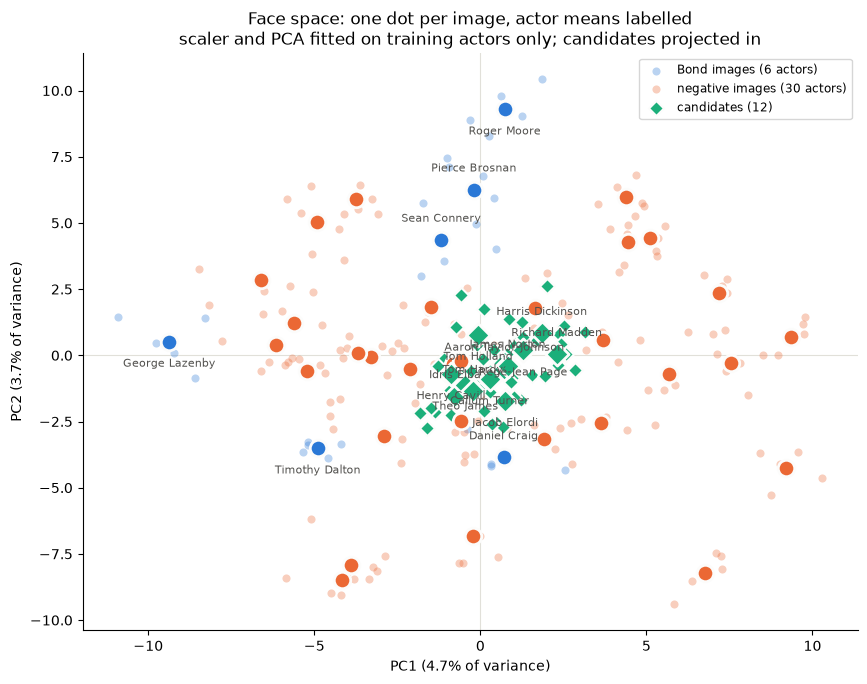

In [121]:
# (a) Face space -- scaler and PCA fitted on TRAINING images only, candidates
# projected into the same space afterwards.
scale = StandardScaler().fit(X_tr)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(scale.transform(X_tr))
P_tr = pca2.transform(scale.transform(X_tr))
P_cand = pca2.transform(scale.transform(X_cand))
is_bond_img = y_tr == 1

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axhline(0, color=GRID, linewidth=0.8, zorder=0)
ax.axvline(0, color=GRID, linewidth=0.8, zorder=0)
ax.scatter(P_tr[is_bond_img, 0], P_tr[is_bond_img, 1], s=34, c=C_BOND, alpha=0.32,
           linewidths=0, label=f"Bond images ({len(set(g_tr[y_tr == 1]))} actors)")
ax.scatter(P_tr[~is_bond_img, 0], P_tr[~is_bond_img, 1], s=34, c=C_NEG, alpha=0.32,
           linewidths=0, label=f"negative images ({len(set(acts[y_act == 0]))} actors)")
ax.scatter(P_cand[:, 0], P_cand[:, 1], s=58, c=C_CAND, marker="D",
           edgecolors=SURFACE, linewidths=1.5, label=f"candidates ({len(cand_ids)})")

# Label the six Bonds and the candidates. The negatives are the background mass,
# so they stay unlabelled -- 40+ names in this space is a pile-up, not a chart.
for k, actor in enumerate(list(acts[y_act == 1]) + list(acts[y_act == 0])):
    colour = C_BOND if int(y_act[acts == actor][0]) == 1 else C_NEG
    m = P_tr[g_tr == actor].mean(axis=0)
    ax.scatter(*m, s=140, c=colour, edgecolors=SURFACE, linewidths=2, zorder=5)
    if colour == C_BOND:
        dy = 13 if k % 2 == 0 else -18
        ax.annotate(name_of(actor), m, xytext=(0, dy), textcoords="offset points",
                    ha="center", fontsize=8, color=INK_2, zorder=6)
for k, actor in enumerate(cand_ids):
    m = P_cand[g_cand == actor].mean(axis=0)
    ax.scatter(*m, s=140, c=C_CAND, marker="D", edgecolors=SURFACE, linewidths=2,
               zorder=5)
    dy = 13 if k % 2 == 0 else -18
    ax.annotate(name_of(actor), m, xytext=(0, dy), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2, zorder=6)

var = pca2.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({var[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f}% of variance)")
ax.set_title("Face space: one dot per image, actor means labelled\n"
             "scaler and PCA fitted on training actors only; candidates projected in")
ax.legend(loc="best", fontsize=8.5)
tidy(ax)
plt.savefig(FIGURES / "pca_face_space.png", dpi=150, bbox_inches="tight")
plt.show()

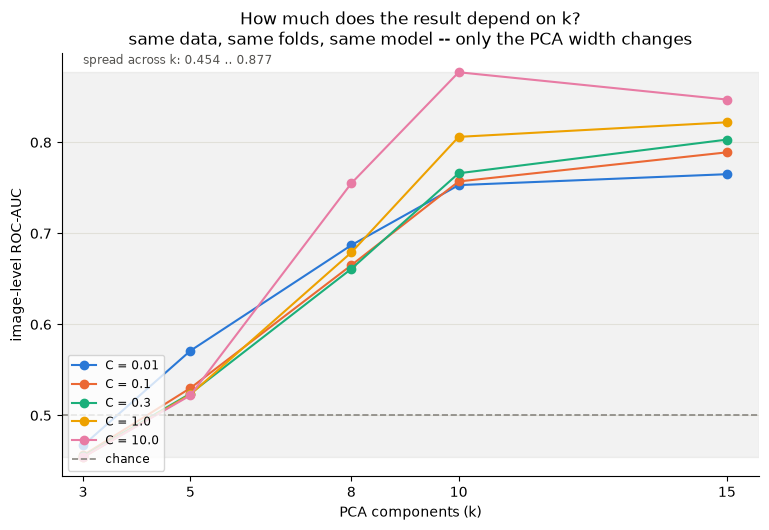

In [122]:
# (b) AUC against the number of PCA components -- one line per C, with the
# min-max spread across k shaded. A tall shaded band means the setting is noise.
fig, ax = plt.subplots(figsize=(9, 5.5))
lo, hi = sweep["roc_auc"].min(), sweep["roc_auc"].max()
ax.axhspan(lo, hi, color=MUTED, alpha=0.10, zorder=0)
ax.annotate(f"spread across k: {lo:.3f} .. {hi:.3f}", xy=(K_GRID[0], hi),
            xytext=(0, 6), textcoords="offset points", fontsize=8.5, color=INK_2)
line_colours = {"0.01": C_BOND, "0.1": C_NEG, "0.3": C_CAND,
                "1.0": "#eda100", "10.0": "#e87ba4"}
for C in sorted(sweep["C"].unique()):
    sub = sweep[sweep["C"] == C].sort_values("k")
    ax.plot(sub["k"], sub["roc_auc"], marker="o", markersize=6,
            color=line_colours[str(C)], label=f"C = {C}")
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1.2, label="chance")
ax.set_xticks(K_GRID)
ax.set_xlabel("PCA components (k)")
ax.set_ylabel("image-level ROC-AUC")
ax.set_title("How much does the result depend on k?\n"
             "same data, same folds, same model -- only the PCA width changes")
ax.set_xlim(K_GRID[0] - 0.4, K_GRID[-1] + 0.6)
ax.legend(loc="lower left", fontsize=8.5)
tidy(ax, grid_axis="y")
plt.savefig(FIGURES / "auc_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

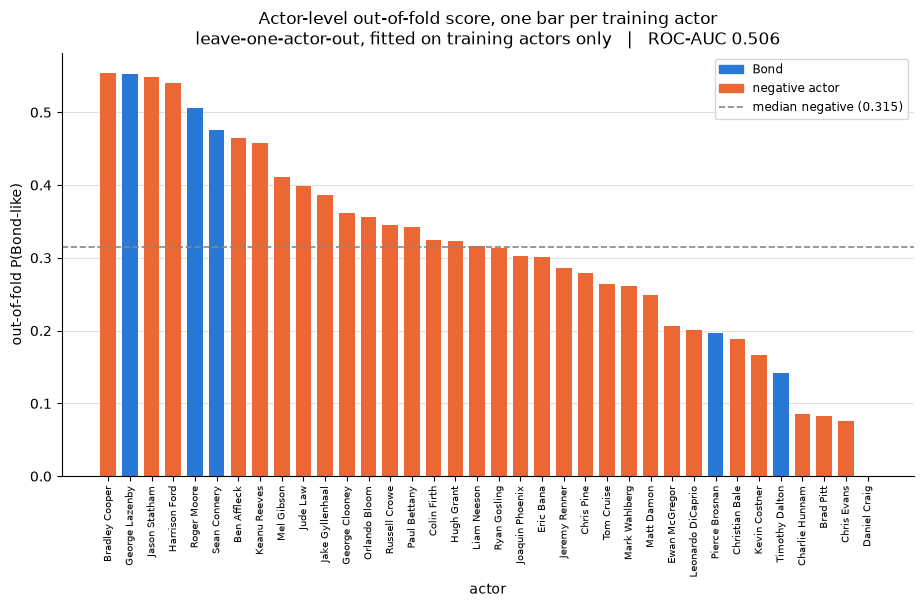

In [123]:
# (c) One bar per TRAINING actor, sorted, Bonds against negatives, with the
# median negative as the reference line.
order = np.argsort(-act_scores)
bar_colours = [C_BOND if y_act[i] == 1 else C_NEG for i in order]
median_neg = float(np.median(act_scores[y_act == 0]))

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(order))
ax.bar(x, act_scores[order], color=bar_colours, width=0.72)
ax.axhline(median_neg, color=MUTED, linestyle="--", linewidth=1.2,
           label=f"median negative ({median_neg:.3f})")
ax.set_xticks(x)
ax.set_xticklabels([name_of(a) for a in acts[order]], rotation=90, fontsize=7.5)
ax.set_ylabel("out-of-fold P(Bond-like)")
ax.set_xlabel("actor")
ax.set_title("Actor-level out-of-fold score, one bar per training actor\n"
             f"leave-one-actor-out, fitted on training actors only   "
             f"|   ROC-AUC {act_auc:.3f}")
handles = [plt.Rectangle((0, 0), 1, 1, color=C_BOND, label="Bond"),
           plt.Rectangle((0, 0), 1, 1, color=C_NEG, label="negative actor")]
ax.legend(handles=handles + ax.get_legend_handles_labels()[0], loc="upper right",
          fontsize=8.5)
tidy(ax, grid_axis="y")
plt.savefig(FIGURES / "actor_scores.png", dpi=150, bbox_inches="tight")
plt.show()

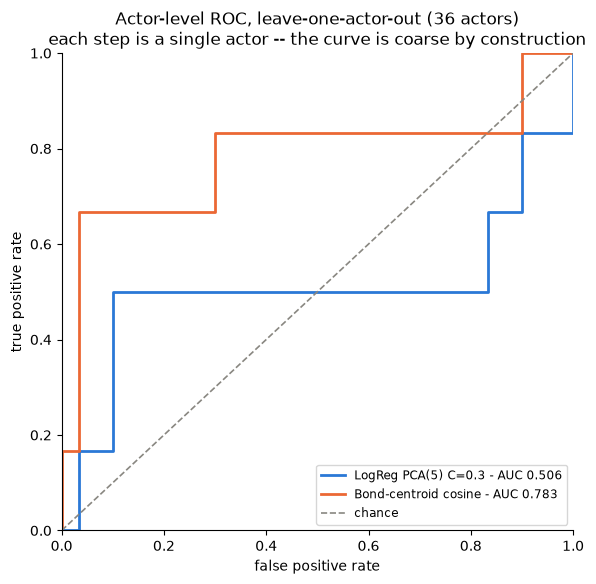

In [124]:
# (d) Actor-level ROC: logistic regression against the training-free centroid.
fig, ax = plt.subplots(figsize=(6.6, 6.2))
for scores, name, colour in [(act_scores, f"LogReg PCA({K_PCA}) C={C_LOGREG}", C_BOND),
                             (act_base, "Bond-centroid cosine", C_NEG)]:
    fpr, tpr, _ = roc_curve(y_act, scores)
    ax.plot(fpr, tpr, color=colour, linewidth=2,
            label=f"{name} - AUC {roc_auc_score(y_act, scores):.3f}")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="chance")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title(f"Actor-level ROC, leave-one-actor-out ({len(acts)} actors)\n"
             "each step is a single actor -- the curve is coarse by construction")
ax.legend(loc="lower right", fontsize=8.5)
tidy(ax)
plt.savefig(FIGURES / "actor_roc.png", dpi=150, bbox_inches="tight")
plt.show()

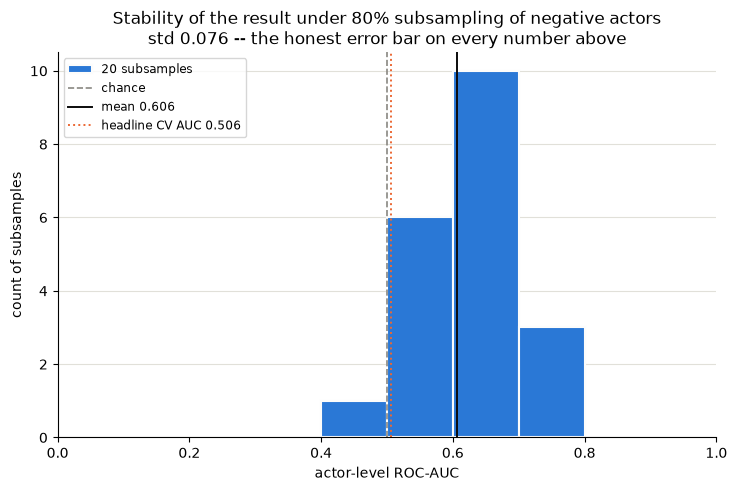

In [125]:
# (e) The 20 subsample AUCs from section 9 -- this is the error bar on the
# headline number.
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.hist(rep_auc, bins=10, range=(0.0, 1.0), color=C_BOND, edgecolor=SURFACE,
        linewidth=1.5, label=f"{N_REPEATS} subsamples")
ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1.2, label="chance")
ax.axvline(rep_auc.mean(), color=INK, linewidth=1.4,
           label=f"mean {rep_auc.mean():.3f}")
ax.axvline(act_auc, color=C_NEG, linewidth=1.4, linestyle=":",
           label=f"headline CV AUC {act_auc:.3f}")
ax.set_xlim(0, 1)
ax.set_xlabel("actor-level ROC-AUC")
ax.set_ylabel("count of subsamples")
ax.set_title("Stability of the result under 80% subsampling of negative actors\n"
             f"std {rep_auc.std():.3f} -- the honest error bar on every number above")
ax.legend(loc="upper left", fontsize=8.5)
tidy(ax, grid_axis="y")
plt.savefig(FIGURES / "repeated_auc.png", dpi=150, bbox_inches="tight")
plt.show()

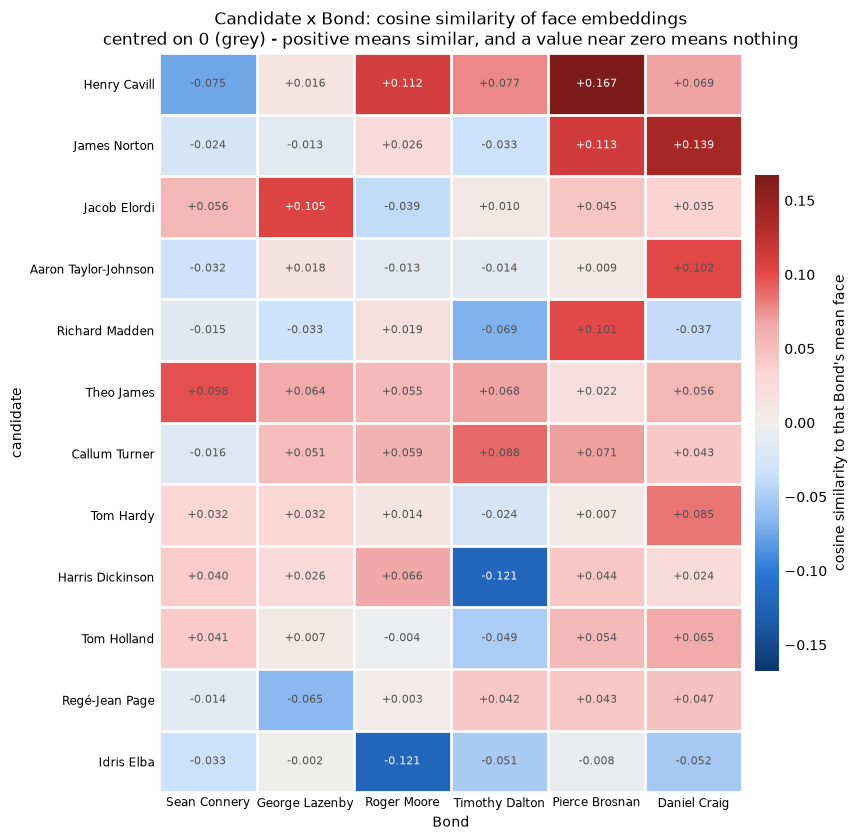

In [126]:
# (f) Candidate x Bond cosine similarity, diverging around zero. Every candidate
# present is shown (the heatmap is about faces, not about the scoring gate);
# rows are marked when the candidate has too few photos to be scored.
import matplotlib.colors as mcolors

heat_ids = cand_ids
# Bonds in cast order, not alphabetical -- they are a sequence, so show it.
_bond_year = dict(zip(actors["actor_id"], actors.get("firstBondYear", np.nan)))
bond_ids = sorted(bond_means, key=lambda b: (_bond_year.get(b) is None,
                                            _bond_year.get(b, 0) or 0, b))
M = np.array([[float((X_cand[g_cand == a] @ bond_means[b]).mean()) for b in bond_ids]
              for a in heat_ids]) if heat_ids else np.zeros((0, len(bond_ids)))

if M.size == 0:
    print("no candidate images: heatmap skipped")
else:
    vmax = max(float(np.abs(M).max()), 1e-6)
    norm = mcolors.TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
    cmap = mcolors.LinearSegmentedColormap.from_list("bond_div", DIVERGING)

    row_order = np.argsort(-M.max(axis=1))
    M = M[row_order]
    row_ids = [heat_ids[i] for i in row_order]

    fig, ax = plt.subplots(figsize=(8, 0.55 * len(row_ids) + 3))
    im = ax.imshow(M, cmap=cmap, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            strong = abs(norm(M[i, j]) - 0.5) * 2 > 0.62
            ax.text(j, i, f"{M[i, j]:+.3f}", ha="center", va="center",
                    fontsize=8, color=SURFACE if strong else INK_2)

    n_per = {a: int((g_cand == a).sum()) for a in row_ids}
    ax.set_yticks(np.arange(len(row_ids)))
    ax.set_yticklabels([f"{name_of(a)}" + ("" if n_per[a] >= MIN_CAND_IMAGES
                                           else f"  (only {n_per[a]} photo"
                                                + ("s)" if n_per[a] != 1 else ")"))
                        for a in row_ids], fontsize=8.5)
    ax.set_xticks(np.arange(len(bond_ids)))
    ax.set_xticklabels([name_of(b) for b in bond_ids], fontsize=8.5)
    ax.set_xticks(np.arange(-0.5, len(bond_ids), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(row_ids), 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)

    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cbar.set_label("cosine similarity to that Bond's mean face")
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0)
    ax.set_xlabel("Bond")
    ax.set_ylabel("candidate")
    ax.set_title("Candidate x Bond: cosine similarity of face embeddings\n"
                 "centred on 0 (grey) - positive means similar, and a value near "
                 "zero means nothing")
    plt.savefig(FIGURES / "candidate_bond_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

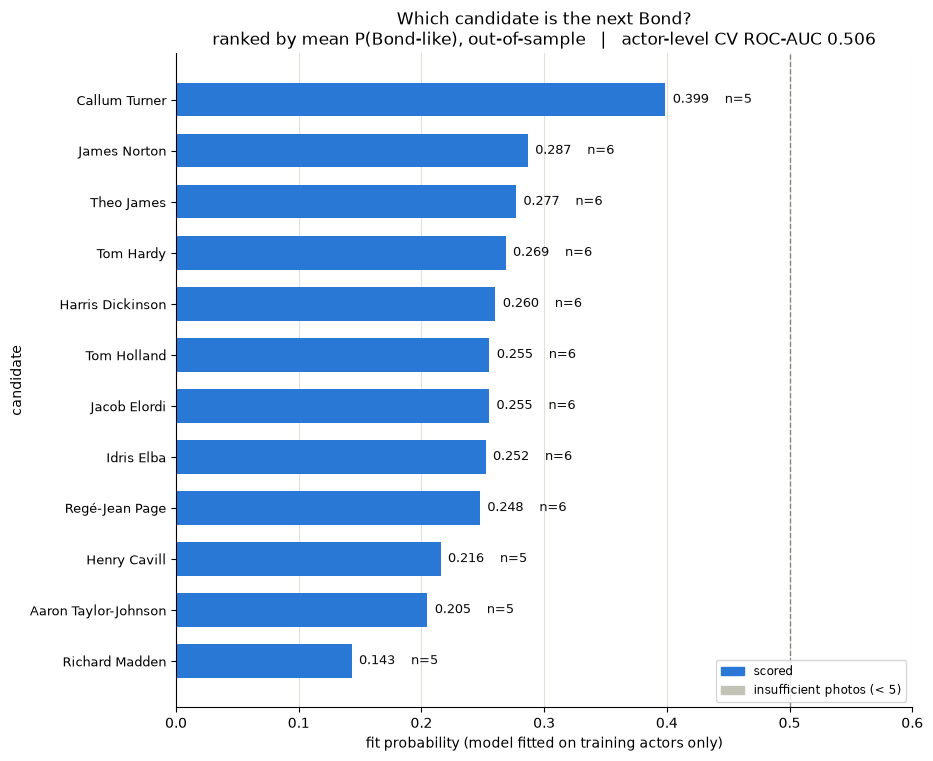

In [127]:
# (g) The answer: candidates ranked by fit_probability. Candidates with too few
# photos are greyed out and carry their count instead of a score.
ranked = pd.concat([
    cand_table.assign(greyed=False),
    cand_short.assign(greyed=True, fit_probability=np.nan),
], ignore_index=True) if len(cand_table) else cand_short.assign(
    greyed=True, fit_probability=np.nan)

if len(ranked) == 0:
    print("no candidates to plot")
else:
    ranked["_key"] = ranked["fit_probability"].fillna(-1.0)
    ranked = ranked.sort_values("_key", ascending=False).reset_index(drop=True)

    y = np.arange(len(ranked))
    vals = ranked["fit_probability"].fillna(0.0).to_numpy()
    colours = [GREYED if g else C_BOND for g in ranked["greyed"]]

    fig, ax = plt.subplots(figsize=(9.5, 0.5 * len(ranked) + 2.5))
    ax.barh(y, vals, color=colours, height=0.66)
    for i, r in ranked.iterrows():
        # n_images on every bar, so a score can be read against its evidence.
        if r["greyed"]:
            ax.text(0.006, y[i], f"insufficient photos  (n={int(r['n_images'])})",
                    va="center", ha="left", fontsize=8.5, color=MUTED)
        else:
            ax.text(r["fit_probability"] + 0.006, y[i],
                    f"{r['fit_probability']:.3f}    n={int(r['n_images'])}",
                    va="center", ha="left", fontsize=9, color=INK)

    ax.set_yticks(y)
    ax.set_yticklabels([name_of(a) for a in ranked["actor_id"]], fontsize=9.5)
    ax.invert_yaxis()
    ax.set_xlabel("fit probability (model fitted on training actors only)")
    ax.set_ylabel("candidate")
    ax.set_xlim(0, max(0.6, float(vals.max()) * 1.25 if vals.size else 0.6))
    ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1.0)
    ax.set_title("Which candidate is the next Bond?\n"
                 f"ranked by mean P(Bond-like), out-of-sample   |   "
                 f"actor-level CV ROC-AUC {act_auc:.3f}")
    handles = [plt.Rectangle((0, 0), 1, 1, color=C_BOND, label="scored"),
               plt.Rectangle((0, 0), 1, 1, color=GREYED,
                             label=f"insufficient photos (< {MIN_CAND_IMAGES})")]
    ax.legend(handles=handles, loc="lower right", fontsize=8.5)
    tidy(ax, grid_axis="x")
    plt.savefig(FIGURES / "candidate_ranking.png", dpi=150, bbox_inches="tight")
    plt.show()

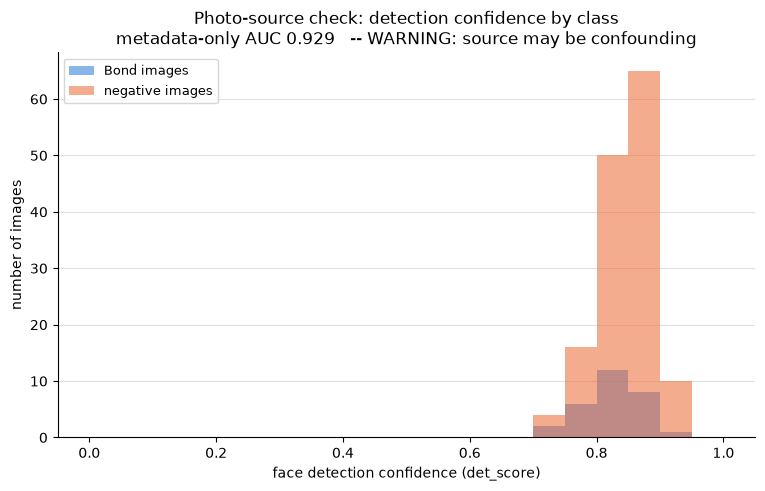

In [128]:
# (h) Photo-source diagnostic: detector confidence for Bond vs negative images.
# Separated distributions are the warning sign from section 10.
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0.0, 1.0, 21)
ax.hist(train_frame.loc[y_tr == 1, "det_score"], bins=bins, color=C_BOND, alpha=0.55,
        label="Bond images")
ax.hist(train_frame.loc[y_tr == 0, "det_score"], bins=bins, color=C_NEG, alpha=0.55,
        label="negative images")
ax.set_xlabel("face detection confidence (det_score)")
ax.set_ylabel("number of images")
ax.set_title("Photo-source check: detection confidence by class\n"
             f"metadata-only AUC {meta_auc:.3f}"
             + ("   -- WARNING: source may be confounding" if meta_auc > 0.65
                else "   -- no strong source signal"))
ax.legend(loc="upper left", fontsize=9)
tidy(ax, grid_axis="y")
plt.savefig(FIGURES / "photo_source.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Caveats

**What this notebook can say**
- How well Bond-ness is ranked across *actors* under leave-one-actor-out CV, with
  the spread from repeated subsampling attached to it.
- Whether the training-free centroid baseline is competitive.
- Whether the photos themselves — not the faces — carry the label.
- Which candidates the model rates highest, among those with enough photos.

**What it cannot say**
- **It is not a casting judgement.** The score is *resemblance to the six past
  Bonds as photographed here*.
- **Six positives, one background.** All six are white male actors, mostly
  English/Irish, filmed by the same franchise. The model can learn "looks like
  this specific cohort" and still be useless for a real casting question. More
  negatives do not fix that confound.
- **`nearest Bond` is only reported when it means something.** Cosines near zero
  are an argmax over noise; a "closest Bond" at a cosine of 0.05 is not a fact
  about anyone's face and is suppressed above (`COSINE_MEANINGFUL = 0.30`).
- **The candidate scores are not calibrated.** They are a ranking key, not a
  probability. Do not read `0.62` as "62% likely to be cast".
- **A candidate with fewer than 10 photos is not scored at all.** One photo is
  one photo.
- **AUC hides the person.** A single hard actor can move it by several points;
  the per-Bond ranks and the repeated-subsample std are part of the result, not
  decoration.

**Highest-value next steps**
1. **Real negatives, deliberately varied** — 25+ non-Bond actors, varied in age,
   ethnicity and look, photographed on the same terms as the Bonds.
2. **More photos per candidate** — 10+ each, so the mean is an average of a face.
3. **Match the photo sources** across both classes, or the section 10 check will
   keep firing.
4. **Calibrate** (`CalibratedClassifierCV`) before using `fit_probability` as
   anything other than a ranking key.